# Avance de Proyecto — Corte 1
## Segmentación de pacientes en riesgo de diabetes mediante clustering
## Alean Alvarez Olivero
**Asignatura:** Minería de Datos (VIRTUAL-25158) — Universidad de la Costa
**Tipo de proyecto:** Clustering (segmentación de pacientes)
**Dataset:** CDC Diabetes Health Indicators (BRFSS 2015) — Kaggle / UCI Machine Learning Repository



## 1. Descripción del dataset

El conjunto de datos CDC Diabetes Health Indicators proviene de la encuesta telefónica
anual Behavioral Risk Factor Surveillance System (BRFSS), realizada en 2015 por los
Centros para el Control y la Prevención de Enfermedades (CDC) de Estados Unidos. Contiene
53.680 registros y 22 columnas: una variable relacionada con el diagnóstico de
diabetes (`Diabetes_binary`) y 21 variables demográficas, de estilo de vida y clínicas,
autorreportadas por los encuestados.

Para este proyecto no se utilizará `Diabetes_binary` como variable objetivo (ya que el
proyecto es de clustering, no de clasificación); en su lugar, se usará como referencia
descriptiva para interpretar los perfiles o clústeres que resulten del análisis.

**Fuente:** https://www.kaggle.com/datasets/alexteboul/diabetes-health-indicators-dataset


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style("whitegrid")
pd.set_option("display.max_columns", None)

# Ajusta la ruta según donde hayas guardado el archivo descargado de Kaggle
RUTA_DATOS = "diabetes_012_health_indicators_BRFSS2015.csv"

df = pd.read_csv(RUTA_DATOS)
print(f"Filas: {df.shape[0]:,}  |  Columnas: {df.shape[1]}")
df.head()

Filas: 105,280  |  Columnas: 22


,Diabetes_012,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,Veggies,HvyAlcoholConsump,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,1.0,1.0,40.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,5.0,18.0,15.0,1.0,0.0,9.0,4.0,3.0
1,0.0,0.0,0.0,0.0,25.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,3.0,0.0,0.0,0.0,0.0,7.0,6.0,1.0
2,0.0,1.0,1.0,1.0,28.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,5.0,30.0,30.0,1.0,0.0,9.0,4.0,8.0
3,0.0,1.0,0.0,1.0,27.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,2.0,0.0,0.0,0.0,0.0,11.0,3.0,6.0
4,0.0,1.0,1.0,1.0,24.0,0.0,0.0,0.0,1.0,1.0,1.0,0.0,1.0,0.0,2.0,3.0,0.0,0.0,0.0,11.0,5.0,4.0


## 2. Descripción de variables

| Variable | Descripción | Tipo | Valores |
|---|---|---|---|
| Diabetes_012 / Diabetes_binary | Diagnóstico de diabetes (referencia, no se usa como target en clustering) | Categórica | 0 = no, 1 = prediabetes, 2 = diabetes (o 0/1 en la versión binaria) |
| HighBP | Presión arterial alta | Binaria | 0 = no, 1 = sí |
| HighChol | Colesterol alto | Binaria | 0 = no, 1 = sí |
| CholCheck | Chequeo de colesterol en los últimos 5 años | Binaria | 0 = no, 1 = sí |
| BMI | Índice de masa corporal | Numérica continua | valores enteros |
| Smoker | Ha fumado al menos 100 cigarrillos en su vida | Binaria | 0 = no, 1 = sí |
| Stroke | Ha tenido un accidente cerebrovascular | Binaria | 0 = no, 1 = sí |
| HeartDiseaseorAttack | Enfermedad coronaria o infarto | Binaria | 0 = no, 1 = sí |
| PhysActivity | Actividad física en los últimos 30 días | Binaria | 0 = no, 1 = sí |
| Fruits | Consume fruta al menos 1 vez al día | Binaria | 0 = no, 1 = sí |
| Veggies | Consume vegetales al menos 1 vez al día | Binaria | 0 = no, 1 = sí |
| HvyAlcoholConsump | Consumo elevado de alcohol | Binaria | 0 = no, 1 = sí |
| AnyHealthcare | Tiene algún tipo de cobertura de salud | Binaria | 0 = no, 1 = sí |
| NoDocbcCost | No pudo ir al médico por costo, en los últimos 12 meses | Binaria | 0 = no, 1 = sí |
| GenHlth | Percepción general de salud | Ordinal | 1 = excelente ... 5 = mala |
| MentHlth | Días de mala salud mental en los últimos 30 días | Numérica discreta | 0–30 |
| PhysHlth | Días de mala salud física en los últimos 30 días | Numérica discreta | 0–30 |
| DiffWalk | Dificultad seria para caminar o subir escaleras | Binaria | 0 = no, 1 = sí |
| Sex | Sexo | Binaria | 0 = mujer, 1 = hombre |
| Age | Categoría de edad (rangos de 5 años) | Ordinal | 1 = 18-24 ... 13 = 80+ |
| Education | Nivel educativo alcanzado | Ordinal | 1 a 6 |
| Income | Nivel de ingreso del hogar | Ordinal | 1 a 8 |

*(Diccionario elaborado a partir de la documentación oficial del dataset en Kaggle/UCI.)*

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 105280 entries, 0 to 105279
Data columns (total 22 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   Diabetes_012          105280 non-null  float64
 1   HighBP                105280 non-null  float64
 2   HighChol              105280 non-null  float64
 3   CholCheck             105280 non-null  float64
 4   BMI                   105280 non-null  float64
 5   Smoker                105280 non-null  float64
 6   Stroke                105280 non-null  float64
 7   HeartDiseaseorAttack  105280 non-null  float64
 8   PhysActivity          105279 non-null  float64
 9   Fruits                105279 non-null  float64
 10  Veggies               105279 non-null  float64
 11  HvyAlcoholConsump     105279 non-null  float64
 12  AnyHealthcare         105279 non-null  float64
 13  NoDocbcCost           105279 non-null  float64
 14  GenHlth               105279 non-null  float64
 15  

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Diabetes_012,105280.0,0.296068,0.697028,0.0,0.0,0.0,0.0,2.0
HighBP,105280.0,0.432048,0.495363,0.0,0.0,0.0,1.0,1.0
HighChol,105280.0,0.430557,0.495156,0.0,0.0,0.0,1.0,1.0
CholCheck,105280.0,0.964229,0.185720,0.0,1.0,1.0,1.0,1.0
BMI,105280.0,28.425722,7.137767,12.0,24.0,27.0,31.0,98.0
Smoker,105280.0,0.446020,0.497080,0.0,0.0,0.0,1.0,1.0
Stroke,105280.0,0.041204,0.198764,0.0,0.0,0.0,0.0,1.0
HeartDiseaseorAttack,105280.0,0.093038,0.290487,0.0,0.0,0.0,0.0,1.0
PhysActivity,105279.0,0.762156,0.425765,0.0,1.0,1.0,1.0,1.0
Fruits,105279.0,0.639197,0.480236,0.0,0.0,1.0,1.0,1.0


## 3. Diagnóstico inicial de calidad de datos

Se revisan valores nulos, filas duplicadas, tipos de datos y posibles valores atípicos en
las variables numéricas continuas (`BMI`, `MentHlth`, `PhysHlth`).

In [5]:
# Valores nulos por columna
nulos = df.isnull().sum()
print("Valores nulos por columna:")
print(nulos[nulos > 0] if nulos.sum() > 0 else "No se encontraron valores nulos.")

Valores nulos por columna:
PhysActivity         1
Fruits               1
Veggies              1
HvyAlcoholConsump    1
AnyHealthcare        1
NoDocbcCost          1
GenHlth              1
MentHlth             1
PhysHlth             1
DiffWalk             1
Sex                  1
Age                  1
Education            1
Income               1
dtype: int64


In [ ]:
# Filas duplicadas
n_duplicados = df.duplicated().sum()
print(f"Filas completamente duplicadas: {n_duplicados}")

In [6]:
# Revisión de rangos válidos declarados en el dataset
rangos_esperados = {
    "BMI": (12, 98),
    "GenHlth": (1, 5),
    "MentHlth": (0, 30),
    "PhysHlth": (0, 30),
    "Age": (1, 13),
    "Education": (1, 6),
    "Income": (1, 8),
}

for col, (minimo, maximo) in rangos_esperados.items():
    fuera_de_rango = df[(df[col] < minimo) | (df[col] > maximo)].shape[0]
    print(f"{col}: {fuera_de_rango} registros fuera del rango esperado [{minimo}, {maximo}]")

BMI: 0 registros fuera del rango esperado [12, 98]
GenHlth: 0 registros fuera del rango esperado [1, 5]
MentHlth: 0 registros fuera del rango esperado [0, 30]
PhysHlth: 0 registros fuera del rango esperado [0, 30]
Age: 0 registros fuera del rango esperado [1, 13]
Education: 0 registros fuera del rango esperado [1, 6]
Income: 0 registros fuera del rango esperado [1, 8]


In [ ]:
# Boxplots para detectar valores atípicos en variables continuas
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, ["BMI", "MentHlth", "PhysHlth"]):
    sns.boxplot(y=df[col], ax=ax, color="#4C72B0")
    ax.set_title(f"Distribución de {col}")
plt.tight_layout()
plt.show()

## 4. Limpieza inicial

Para esta primera etapa se realizan tareas básicas de limpieza: eliminación de duplicados
(si existen), verificación de tipos de dato y creación de un dataframe de trabajo
(`df_clean`) que se usará en los siguientes cortes para la preparación de datos y el
modelado de clustering.

In [15]:
columnas_binarias = ["HighBP", "HighChol", "CholCheck", "Smoker", "Stroke",
                      "HeartDiseaseorAttack", "PhysActivity", "Fruits", "Veggies",
                      "HvyAlcoholConsump", "AnyHealthcare", "NoDocbcCost", "DiffWalk", "Sex"]
columnas_ordinales = ["GenHlth", "Age", "Education", "Income"]

print("Valores nulos por columna antes de la limpieza:")
for c in columnas_binarias + columnas_ordinales:
    n_nan = df_clean[c].isna().sum()
    if n_nan > 0:
        print(f"  {c}: {n_nan} valores nulos")

df_clean = df.drop_duplicates().copy()

filas_antes = df_clean.shape[0]
df_clean = df_clean.dropna(subset=columnas_binarias + columnas_ordinales).copy()
filas_despues_nulos = df_clean.shape[0]
print(f"\nFilas eliminadas por valores nulos: {filas_antes - filas_despues_nulos}")

for c in columnas_binarias + columnas_ordinales:
    df_clean[c] = df_clean[c].astype(int)

print(f"\nFilas antes de limpieza: {df.shape[0]:,}")
print(f"Filas después de limpieza: {df_clean.shape[0]:,}")
df_clean.dtypes

Valores nulos por columna antes de la limpieza:
  PhysActivity: 1 valores nulos
  Fruits: 1 valores nulos
  Veggies: 1 valores nulos
  HvyAlcoholConsump: 1 valores nulos
  AnyHealthcare: 1 valores nulos
  NoDocbcCost: 1 valores nulos
  DiffWalk: 1 valores nulos
  Sex: 1 valores nulos
  GenHlth: 1 valores nulos
  Age: 1 valores nulos
  Education: 1 valores nulos
  Income: 1 valores nulos

Filas eliminadas por valores nulos: 1

Filas antes de limpieza: 105,280
Filas después de limpieza: 98,604


,0
Diabetes_012,float64
HighBP,int64
HighChol,int64
CholCheck,int64
BMI,float64
Smoker,int64
Stroke,int64
HeartDiseaseorAttack,int64
PhysActivity,int64
Fruits,int64


## 5. Primeras visualizaciones

/tmp/ipykernel_1507/3637936748.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=df_clean.iloc[:, 0], palette="Blues")


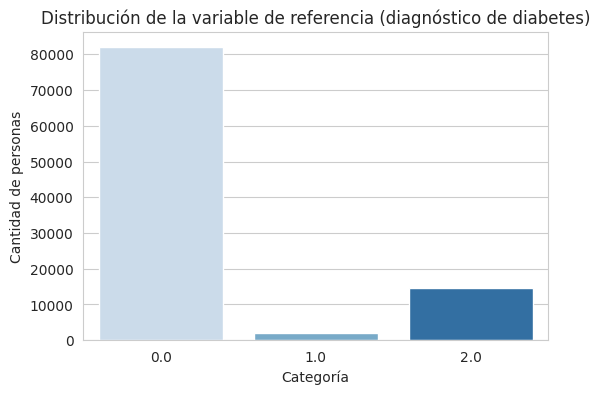

In [10]:
# Distribución de la variable de referencia (diagnóstico de diabetes)
plt.figure(figsize=(6, 4))
sns.countplot(x=df_clean.iloc[:, 0], palette="Blues")
plt.title("Distribución de la variable de referencia (diagnóstico de diabetes)")
plt.xlabel("Categoría")
plt.ylabel("Cantidad de personas")
plt.show()

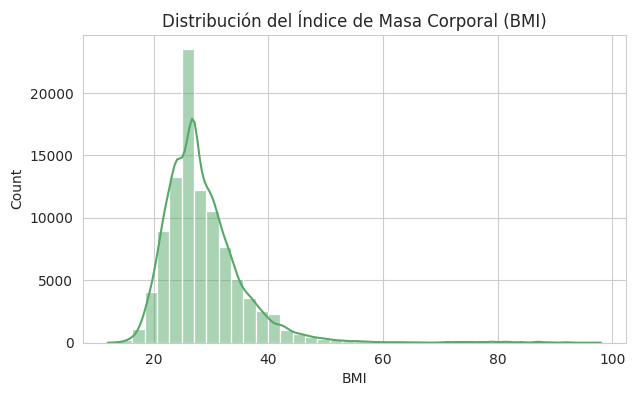

In [11]:
# Distribución del IMC (BMI)
plt.figure(figsize=(7, 4))
sns.histplot(df_clean["BMI"], bins=40, kde=True, color="#55A868")
plt.title("Distribución del Índice de Masa Corporal (BMI)")
plt.xlabel("BMI")
plt.show()

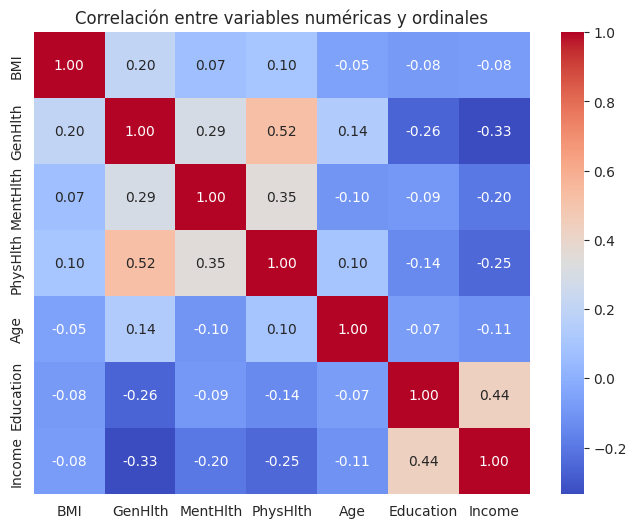

In [12]:
# Mapa de correlación entre variables numéricas/ordinales
variables_num = ["BMI", "GenHlth", "MentHlth", "PhysHlth", "Age", "Education", "Income"]
plt.figure(figsize=(8, 6))
sns.heatmap(df_clean[variables_num].corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Correlación entre variables numéricas y ordinales")
plt.show()

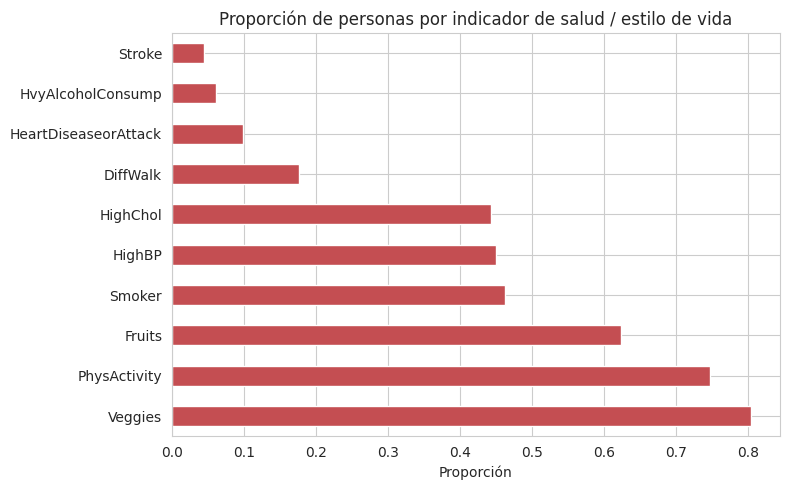

In [13]:
# Prevalencia de condiciones de salud e indicadores de estilo de vida
condiciones = ["HighBP", "HighChol", "Smoker", "Stroke", "HeartDiseaseorAttack",
               "PhysActivity", "Fruits", "Veggies", "HvyAlcoholConsump", "DiffWalk"]

proporciones = df_clean[condiciones].mean().sort_values(ascending=False)

plt.figure(figsize=(8, 5))
proporciones.plot(kind="barh", color="#C44E52")
plt.title("Proporción de personas por indicador de salud / estilo de vida")
plt.xlabel("Proporción")
plt.tight_layout()
plt.show()

## 6. Bitácora de uso de IA
##Promt usado para apoyo y comparacion de informacion y organizacion

Estoy desarrollando un proyecto de minería de datos (primer corte de un curso universitario)
sobre segmentación de pacientes en riesgo de diabetes mediante clustering, usando el dataset
CDC Diabetes Health Indicators (BRFSS 2015, Kaggle/UCI), con 253.680 registros y 21 variables
(demográficas, de estilo de vida y clínicas autorreportadas: HighBP, HighChol, BMI, Smoker,
PhysActivity, GenHlth, Age, Income, etc.).

Quiero que revises y compares tu enfoque con el que ya tengo, para el primer corte, que incluye:
1. Descripción del dataset y diccionario de variables
2. Diagnóstico de calidad de datos (nulos, duplicados, rangos válidos, outliers)
3. Limpieza inicial
4. Primeras visualizaciones (distribuciones, correlaciones, prevalencia de indicadores)

Preguntas específicas:
- ¿Qué variables recomendarías priorizar o descartar para un clustering de perfiles de riesgo
  de diabetes, y por qué?
- ¿Qué técnica de preprocesamiento (escalado, codificación) sugerirías para esta mezcla de
  variables binarias, ordinales y continuas antes de aplicar K-Means?
- ¿Qué método(s) de clustering recomendarías para el siguiente corte, dado este tipo de datos?
- ¿Ves algún error conceptual o de calidad de datos que debería revisar?

Dame tu análisis independiente, sin asumir que mi enfoque actual es correcto.

## 7. Conclusión inicial

A partir de esta primera exploración, el conjunto de datos CDC Diabetes Health Indicators
es adecuado para un proyecto de clustering orientado a la segmentación de pacientes
según su riesgo de diabetes: cuenta con un volumen considerable de registros, variables
binarias de estilo de vida y condiciones de salud, y variables ordinales/continuas
(edad, percepción de salud general, IMC) que permiten construir perfiles diferenciados de
pacientes. El diagnóstico inicial de calidad de datos no evidenció valores nulos ni
duplicados relevantes, aunque sí será necesario, en el siguiente corte, revisar con más
detalle la escala de las variables (binarias vs. ordinales vs. continuas) antes de aplicar
los algoritmos de clustering, dado que estos son sensibles a la escala de las variables.
